# Beeswarm Plot

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Places each point along the value axis and nudges overlapping points sideways without overlap, so the swarm's outline traces the distribution. Every point stays visible, unlike random jitter.

## When to use

- Show individual observations and the distribution shape together
- Show small to moderate datasets (up to a few hundred per group)
- Highlight specific items (color by an attribute)

## Avoid when

- There are thousands of points (the swarm overflows its lane)

## Alternatives

- Strip plot
- Violin plot
- Dot strip plot

## Example

Salaries of 250 data scientists by seniority (synthetic), colored by remote vs. on-site.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(23)
levels = {"Junior": 70, "Mid": 95, "Senior": 125, "Lead": 150}
rows = []
for lvl, mu in levels.items():
    n = 62
    rows.append(pd.DataFrame({"level": lvl,
                              "salary_k": rng.normal(mu, mu * 0.13, n),
                              "work": rng.choice(["Remote", "On-site"], n, p=[0.45, 0.55])}))
df = pd.concat(rows, ignore_index=True)
df.groupby("level", sort=False)["salary_k"].median().round(0)

level
Junior     70.0
Mid        96.0
Senior    127.0
Lead      150.0
Name: salary_k, dtype: float64

### Plot

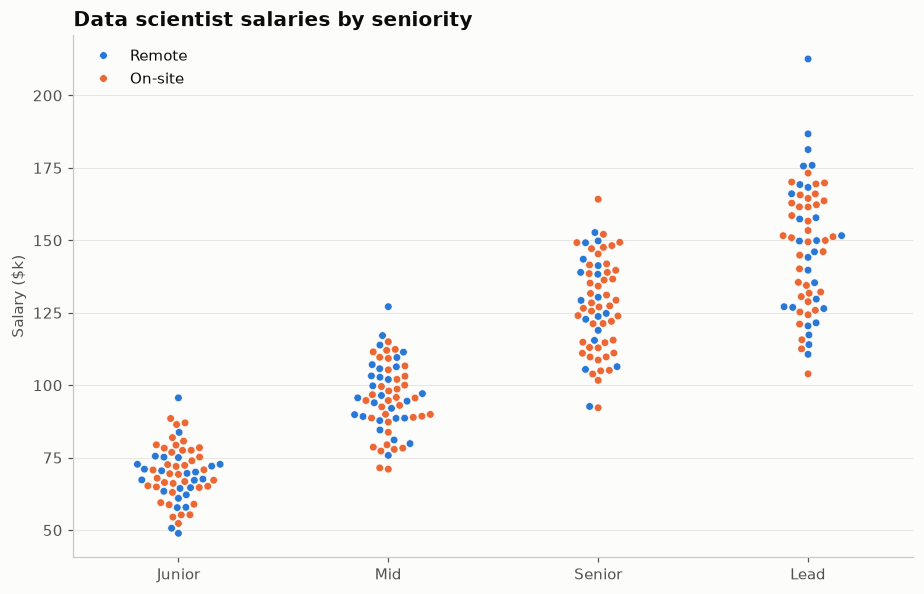

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.swarmplot(data=df, x="level", y="salary_k", hue="work", palette=PALETTE[:2],
              size=5, edgecolor="#fcfcfb", linewidth=0.4, ax=ax)
ax.set_xlabel(None)
ax.set_ylabel("Salary ($k)")
ax.set_title("Data scientist salaries by seniority")
ax.legend(title=None, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

---
Standalone script: [`beeswarm.py`](beeswarm.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)